# Plots Data Story - Research Question 4

The code to generate the plots used in the data story for Research Question 4 is at the end of this notebook.

In [ ]:
# Imports
from scipy.stats import mannwhitneyu

from src.data.loader import load_all_raw_datasets, iterate_parquet_stream
from src.data.preprocessing import apply_data_processing
from src.data.quality_check import check_data_quality_on_datasets
from src.models.log_log_efficiency_model import linear_log_log_model
from src.models.propensity_matching import estimate_propensity_scores, match_nearest_neighbor_within_category
from src.utils.data_utils import calculate_stagnation_rate
from src.utils.general_utils import weighted_percentiles, perform_mannwhitney_test, calculate_smd, check_growth_milestones
from config import (
    DATASET_CHANNELS,
    DATASET_TIMESERIES,
    DATASET_VIDEO_LIGHT
)
from src.utils.plots import *

# Style
sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6 # for reproducing the results

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

## 1. Data Exploration


Our Project will need data from these datasets:
- `df_channels_en.tsv.gz`: Channel data.
- `df_timeseries_en.tsv.gz` : Channel data over time including `delta views`, `delta_videos` and `delta_subs`.
- `yt_metadata_en.jsonl.gz` : Metadata for each video
- `num_comments.tsv.gz` : Number of comments per video.
- `yt_metadata_helper.feather` : A lighter version of video metadata not including description, titles and tags.

Before proceeding please make sure these datasets are located in the `data/raw` folder.

To get a better feel for the datasets, we begin by inspecting each of the datasets.
Our goal in this section is to understand structure, size and feasibility of working with the raw data.

### I. Loading Raw Data

Due to hardware constraints, we initially analyzed the first one million rows of each dataset to understand data structure and variable relationships.

In [ ]:
subset_size = 1_000_000
channels_df, videos_df, videos_light_df, timeseries_df, num_comments_df = load_all_raw_datasets(nrows=subset_size)

### II. Checking data quality

Before deciding on pre-processing the data, it is important to take a look at the quality metrics.

In [3]:
df_list = [channels_df,
           videos_df,
           videos_light_df,
           timeseries_df,
           num_comments_df]

names = ["Channels", "Videos", "Videos (Light)", "Timeseries", "Num Comments"]

check_data_quality_on_datasets(df_list, names)

,Dataset,Rows,Columns,Missing %,Duplicate %,Memory (MB),Numeric Cols,Categorical Cols,Non-Null % (avg),Unique % (avg),Min Numeric,Max Numeric
1,Videos,1000000,8,0.49,0.0,244.93,4,4,99.51,15.34,0.0000,1.101396e+09
3,Timeseries,1000000,10,0.01,0.0,267.69,7,3,99.99,32.20,0.0000,1.334730e+10
2,Videos (Light),1000000,12,0.33,0.0,2447.37,4,8,99.67,38.61,0.0000,1.101396e+09
4,Num Comments,1000000,2,0.00,0.0,72.48,1,1,100.00,50.40,0.0000,2.231960e+05
0,Channels,136470,8,0.01,0.0,41.43,4,4,99.99,42.90,2.0865,1.121395e+08


The quick quality report tells us there are not a lot of missing values. However, we should be aware of that and preprocess the data.

### III. Correlation matrix

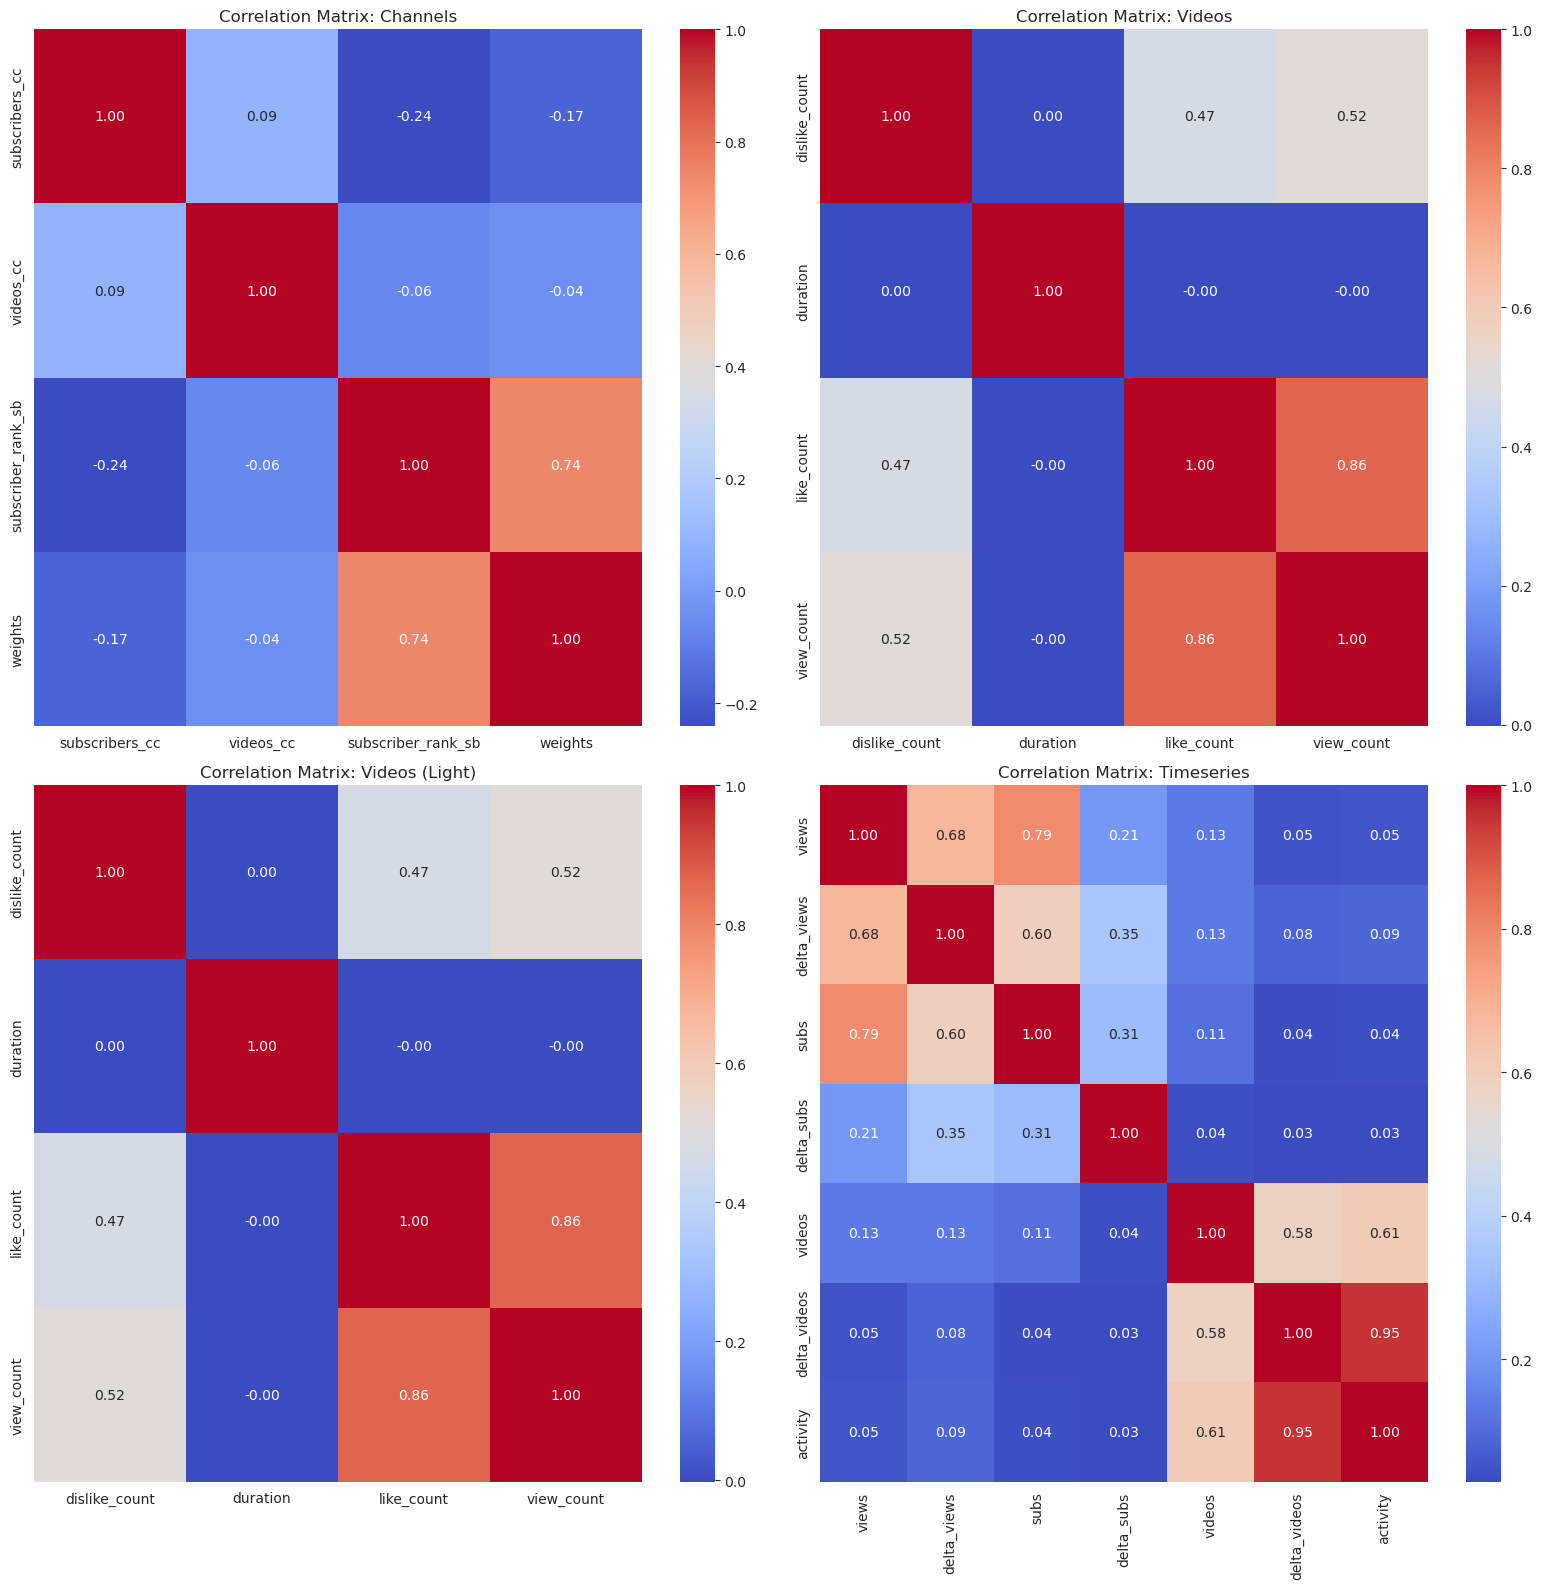

In [4]:
# Filter out the 'Num Comments' dataframe
filtered_df_list = [df for df, name in zip(
    df_list, names) if name != "Num Comments"]
filtered_names = [name for name in names if name != "Num Comments"]

fig = plot_correlation_matrices(filtered_df_list, filtered_names)
plt.show()


First glance insights:
- Channel-level correlations are weak, more uploads don’t clearly relate to more subscribers or better ranks.
- Video-level metrics (views, likes, dislikes) are tightly linked, while duration shows no clear impact on engagement.
- In time-series data, views and subscribers grow together but with only moderate alignment in their weekly changes.

 We note that this subset was not randomly sampled, so correlations are preliminary and may not reflect the global population.

### III. Decisions on Data Preprocessing

Because the dataset is large, we process the data and save the results in Parquet format.
This format allows for faster access and supports iterative reading, which solves the issue of not being able to load everything into memory at once.
The following steps are taken in align with the project goals, code is located in `src/data/preprocessing.py`

#### Cleaning & Storage
We perform standard cleaning for each dataset — removing duplicates, normalizing types and formats, and parsing dates.

Additionally, we created a new lightweight dataset `tags_processed.parquet`, containing only `channel_id`, `display_id`(video_id), `tags`, and `upload_date`.
This dataset will be used later in Research Question 2 to cluster different YouTube categories, and was separated to allow faster processing without reloading the large video metadata file.


##### Feature Engineering
Feature engineering is a key part of our pipeline, as these variables are later reused across multiple analyses.
Bellow are some of the most important ones:

- **Engagement Efficiency (video level)**
  For each video *v*:
  $$
  E_v = \frac{\text{likes}_v + \text{dislikes}_v + \text{comments}_v}{\text{views}_v}
  $$
  This score is used for detecting outperformers, and since it is reused a lot, we decided to include it in our saved processed datasets.

<br>

In `time_series.data`, <br>
we align all events to weekly periods (W-MON) and aggregate per channel:
- `lifetime_reactions_week = Σ(likes + dislikes + comments)` — sum of lifetime reactions for all videos uploaded in that week
- `lifetime_views_week = Σ(views)` — sum of lifetime views for all videos uploaded in that week

Due to the dataset limitations, the engagement metrics (likes, dislikes, comments) in the dataset are snapshot values recorded at crawl time (Oct–Nov 2019), not true time series. Therefore, these weekly aggregates represent the **lifetime engagement totals** of videos uploaded in each week, rather than engagement accumulated during that week. This interpretation is still valuable for analyzing recent creative output and topic shifts over time (supports RQ3).

We then compute:
- **Weekly Efficiency**
$$
E_{\text{week}} = \frac{\text{lifetime\_reactions\_week}}{\text{lifetime\_views\_week}}
$$
- **4-Week Trailing Efficiency**
  A rolling version for smoother trends in the `timeseries` dataset.


- **Channel Aggregates (from processed videos)**
  - `avg_engagement_efficiency` — mean efficiency across all channel videos
  - `total_views`, `total_like_count`, `total_dislike_count`, `total_num_comms` — cumulative metrics
  - `avg_video_like_ratio`, `video_count_processed` — engagement and volume indicators
  - `channel_age_days`, `videos_per_day` — activity and lifespan measures

All processed datasets are saved under `/data/processed/` for efficient downstream use.

## 2. Loading the data


### I. Run the preprocessing pipeline

By running the preprocessing pipeline, it takes each dataset from the `data/raw` folder, preprocesses them and saves them in `data/processed` for later use. Before running the function, please make sure you have the python libraries in `requirements.txt` installed, and you have the original datasets in the `raw` folder.

Depending on the machine, this process can take from 30 minutes to a couple of hours.


In [ ]:
apply_data_processing()

### II. Checking the processed data

In [2]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(6)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.859855,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.932584,40549
5,Entertainment,2007-01-15,UCIwFjwMjI0y7PDBVEO9-bkQ,Justin Bieber,46574085,134,12.0,2.087,4668.0,0.028706,0.025269,5.886436e+08,17697.0,8815774.0,373636.0,719646.0,0.949962,128


In [3]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,2016-07-26,0.049820,0.049820
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,2016-08-02,0.049374,0.049374
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,2016-08-09,0.045413,0.045413
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,2016-08-16,0.046415,0.046415
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,2016-08-23,0.031169,0.031169


In [4]:
timeseries_df.columns

Index(['channel', 'category', 'datetime', 'views', 'delta_views', 'subs',
       'delta_subs', 'videos', 'delta_videos', 'activity', 'week_start',
       'efficiency_4week', 'efficiency_4week_filled'],
      dtype='object')

Datasets that are too large to fit in memory at once like `videos_metadata_processed.parquet`, `videos_light_processed.parquet` and `tags_processed.parquet`, we process iteratively, meaning, we read it by chunks. This ensures that we can use these datasets in our Research Questions and proves feasibility.

_The larger 20GB `videos_metadata_processed.parquet` takes around 30 minutes in our local machines._


In [ ]:
# Example of reading from videos_light_processed.parquet with chunks
for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=20_000_000):
    print(df_chunk.shape)

# 3. Basic information about the data

### I. Subscribers distribution

As our research is focused on working with small- to midsize-channels, it is important to understand overall image of subscribers count.

In [5]:
# Compute weighted 50th (median) and 90th percentiles of subscriber counts
channel_df =  pd.read_parquet(DATASET_CHANNELS)
cuts = weighted_percentiles(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    percentiles=(50, 90)
)
print(cuts)
p50, p90 = cuts[50], cuts[90]

{50: np.float64(22200.0), 90: np.float64(160000.0)}


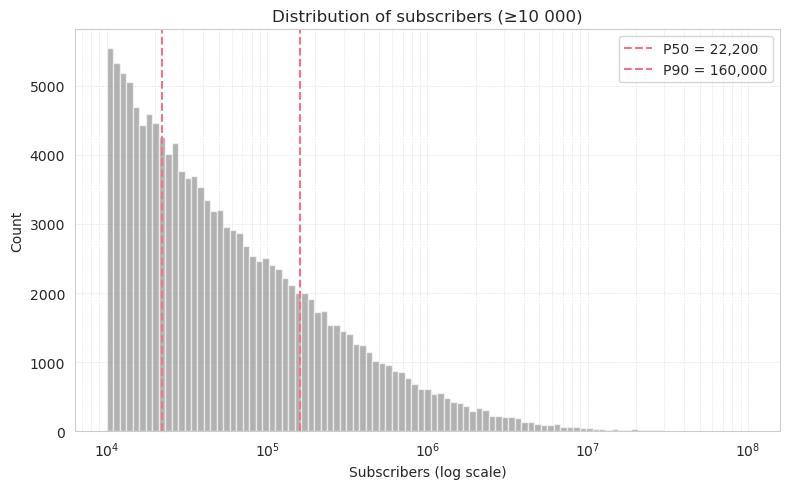

In [6]:
plot_log_histogram(
    channel_df,
    column_name="subscribers_cc",
    percentile_markers={"P50": p50, "P90": p90},
    bins=np.logspace(4, 8, 100),
    plot_title="Distribution of subscribers (≥10 000)",
    x_axis_label="Subscribers (log scale)"
)
plt.show()

The distribution is highly right-skewed (heavy-tailed), most channels cluster near the lower end (10 k – 100 k), and very few extend into the millions.

### II. Average Efficiency by category

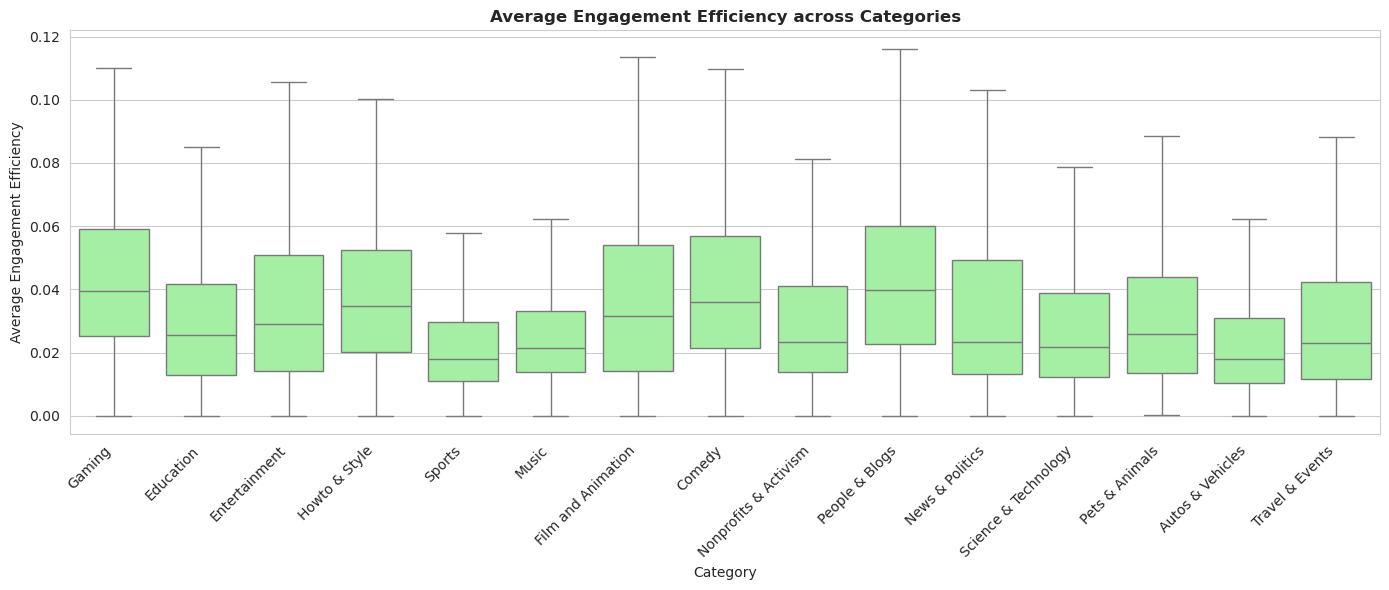

In [7]:
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=channel_df,
    x="category_cc",
    y="avg_engagement_efficiency",
    color="palegreen",
    showfliers=False
)
plt.title("Average Engagement Efficiency across Categories", weight="bold")
plt.xlabel("Category")
plt.ylabel("Average Engagement Efficiency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

This indicates that content type strongly influences how actively viewers engage with creators.

### III. Efficiency overtime

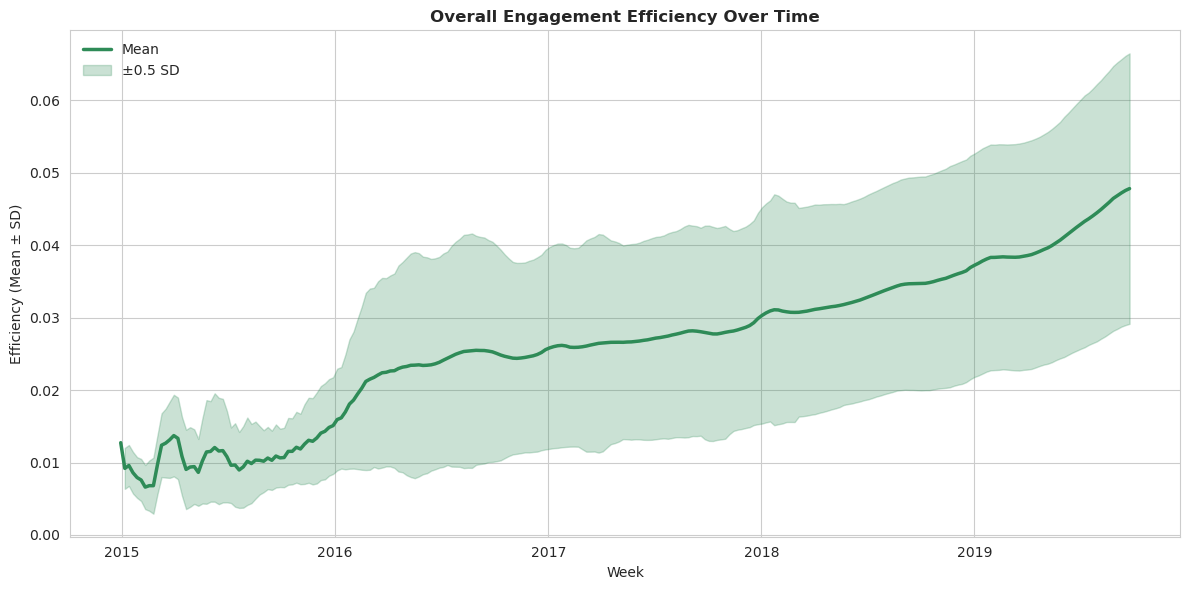

In [8]:
plot_timeseries_trend(
    df=timeseries_df,
    date_col="week_start",
    value_col="efficiency_4week_filled",
    title="Overall Engagement Efficiency Over Time",
    xlabel="Week",
    ylabel="Efficiency (Mean ± SD)",
    smooth=True,
    window=6,
    color="seagreen"
)

The time series shows a clear upward trend in overall engagement efficiency from 2015 to 2019.
This indicates that over time, viewers have become increasingly active in leaving likes, dislikes, and comments relative to the number of views.

# 4. Detecting Outperformers - Research Queston 1

### I. Identifying small to mid sized channels

We define our focus cohort as channels with 10 000–100 000 subscribers. The subscriber distribution is heavy-tailed: the median (P50) is ≈ 22 k and P90 is ≈ 160 k, so 100 k lies well below the top decile while meaningfully above the median. We use 100 k because it:
- aligns with YouTube’s Silver Creator milestone,
- avoids dominance by a small set of very large channels and
 - provides a large, comparable sample of growing creators.

In [9]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### II. Fitting the Model and Detecting the Outperformers

Outperformers are defined as small- to mid-sized channels that achieve an engagement efficiency substantially higher than what is expected for their subscriber size and category, after controlling for the heavy-tailed scaling of engagement on YouTube.

Starting from the efficiency metric that we defined in feature engineering, we continue with:

- **Expected Efficiency Model (Log–Log Linear Regression)**

  To understand how efficiency scales with channel size, we fit a log–log regression:
  $$
  \log_{10}(E_c) = a + b \, \log_{10}(\text{subscribers}_c) + \varepsilon_c
  $$
  Using logs stabilizes the heavy-tailed data and makes the relationship approximately linear.
  This model captures the power-law scaling between engagement and audience size, allowing us to identify channels whose efficiency significantly exceeds the expected baseline for their size.

- **Residual Efficiency (Deviation from Expectation)**

  The residual measures how much a channel over- or under-performs relative to its expected efficiency:
  $$
  r_c = \log_{10}(E_c) - \big(a + b \, \log_{10}(\text{subscribers}_c)\big)
  $$

- **Quiet Outperformers**

  Channels with residuals above a threshold \( \gamma \) (e.g., mean + 2·std or the top 5%) are labeled as outperformers:
  $$
  r_c > \gamma \;\Rightarrow\; \text{quiet outperformer}
  $$

In [10]:
channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,174949.0,2266.0,29914.0,0.986781,16,4.992111,-1.164280,-1.613989,0.449709,1.233636
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,216481.0,19153.0,13512.0,0.978910,267,4.965202,-1.488122,-1.610172,0.122050,0.341271
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,199670.0,5360.0,8565.0,0.965106,35,4.994242,-1.531054,-1.614292,0.083238,0.235570
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,299536.0,13301.0,12879.0,0.970602,52,4.992120,-1.529482,-1.613991,0.084508,0.239030
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,232189.0,17840.0,2423.0,0.899380,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900


The residual distribution is approximately bell-shaped but slightly right-skewed, reflecting that most channels perform near their expected efficiency while a small subset achieve substantially higher engagement relative to size.
We define outperformers as those above the 97th percentile, representing the top 3% of channels with the largest positive deviations.
This stricter cutoff filters out statistical noise and highlights genuinely exceptional channels whose audience engagement is consistently beyond what their subscriber base would predict.

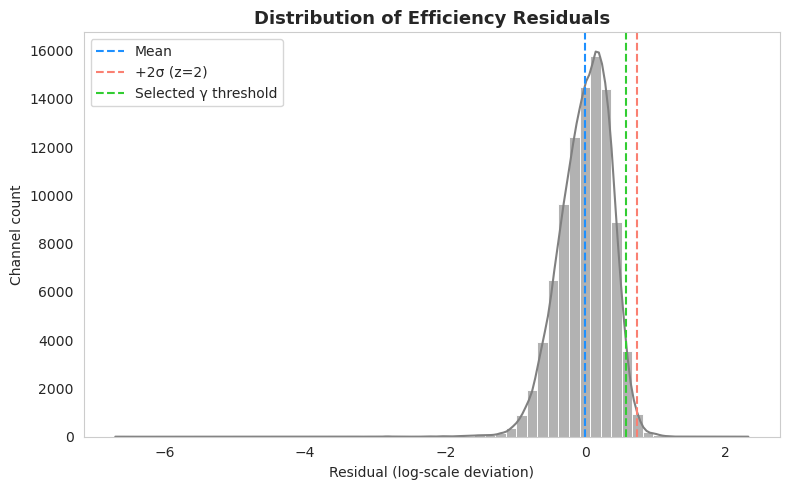

In [11]:
gamma = np.percentile(channels_model["residual"], 97)
plot_residual_distribution(channels_model["residual"], threshold_gamma=gamma)

In [12]:
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)

In [13]:
outperformers_df = channel_df[channel_df['is_outperformer']]
non_outperformers_df = channel_df[~channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,0.996371,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,0.968095,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,0.979401,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,0.995255,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,0.977471,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,0.864303,55,True


#### III. Categories of quiet outperformers

Initially, dataset provides us a correspondence of each channel to 1 of 15 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data. We explore this on Research Question 2._

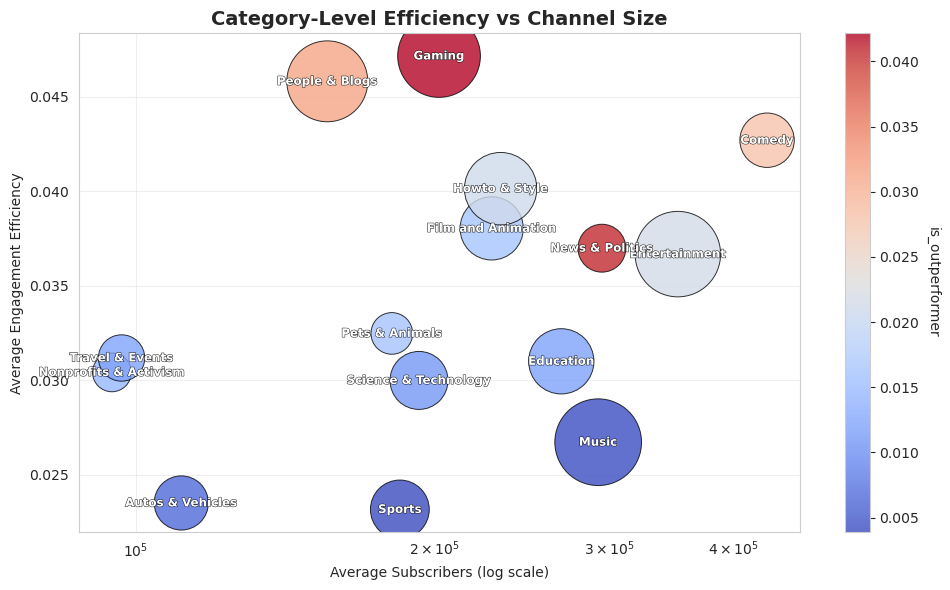

In [14]:
plot_category_bubble(
    dataframe=channel_df,
    size_column="subscribers_cc",
    value_column="avg_engagement_efficiency",
    category_column="category_cc",
    color_column="is_outperformer",  # average will give share of outperformers
    plot_title="Category-Level Efficiency vs Channel Size",
    x_axis_label="Average Subscribers (log scale)",
    y_axis_label="Average Engagement Efficiency",
)

#### IV. Diving into one Outperformer

Let’s take a closer look at one of the top quiet outperformers, the channel “Gym Monk / Gaming.”
This channel still exists today with around 28K subscribers, and during the 2019 period it had multiple videos reaching hundreds of thousands of views.

In [15]:
# Loading the time series data
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)

In [16]:
channel = 'UCfs20O_RuLJXGGTxv5VIzdw'
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]
channel_timeseries.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
12899150,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-04-25,26360.750,63.750,1775.750,0.000,77,0,11,2016-04-19,1.208036,1.208036
12899151,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-02,26807.000,446.250,1795.000,19.250,77,0,6,2016-04-26,NaN,NaN
12899152,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-09,27071.250,264.250,1806.375,11.375,78,1,1,2016-05-03,1.193830,1.193830
12899153,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-16,27407.500,336.250,1814.750,8.375,80,2,3,2016-05-10,1.154780,1.154780
12899154,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-23,28045.125,637.625,1830.125,15.375,84,4,6,2016-05-17,0.880374,0.880374


Let's compare his efficiency(outperformer) to someone who is in the same category "Gaming" and has an average efficiency.


In [17]:
target_channel = "UCfs20O_RuLJXGGTxv5VIzdw"
target_eff = channel_df.loc[channel_df["channel"] == target_channel, "avg_engagement_efficiency"].iloc[0]

# Find average efficiency for Gaming category
avg_eff_gaming = (
    channel_df.loc[channel_df["category_cc"] == "Gaming", "avg_engagement_efficiency"]
    .mean()
)

# Find channel in Gaming closest to that average
avg_channel = (
    channel_df[channel_df["category_cc"] == "Gaming"]
    .assign(diff=lambda x: (x["avg_engagement_efficiency"] - avg_eff_gaming).abs())
    .sort_values("diff")
    .iloc[0]
)

avg_channel_id = avg_channel["channel"]
avg_channel_eff = avg_channel["avg_engagement_efficiency"]

print(f"Matched 'average' Gaming channel: {avg_channel_id}")

Matched 'average' Gaming channel: UCRZ5-H-PV_2jsj3JsB9uU2A


In [18]:
channel_2 = 'UCRZ5-H-PV_2jsj3JsB9uU2A'
channel_timeseries_2 = timeseries_df[timeseries_df['channel'] == channel_2]
channel_timeseries_2.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
8395116,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-02,178813.500,751.500,831.000,0.000,5,0,0,2016-04-26,NaN,NaN
8395117,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-09,180609.500,1796.000,837.750,6.750,5,0,0,2016-05-03,NaN,NaN
8395118,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-16,182562.375,1952.875,845.125,7.375,6,1,1,2016-05-10,0.012577,0.012577
8395119,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-23,184819.000,2256.625,860.000,14.875,7,1,2,2016-05-17,0.010054,0.010054
8395120,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-30,186508.625,1689.625,867.000,7.000,8,1,2,2016-05-24,0.015791,0.015791


H₀ (null hypothesis):
The outperformer’s engagement efficiency over time is not significantly different from that of an average Gaming channel.

H₁ (alternative hypothesis):
The outperformer’s engagement efficiency is significantly higher than that of an average Gaming channel.

In [ ]:
target_ts = timeseries_df.loc[timeseries_df["channel"] == target_channel].copy()
avg_ts = timeseries_df.loc[timeseries_df["channel"] == avg_channel].copy()

# Drop missing values
eff_out = target_ts["efficiency_4week_filled"].dropna()
eff_avg = avg_ts["efficiency_4week_filled"].dropna()

# Mann-Whitney U test (one-sided: outperformer > average)
stat, p_value = mannwhitneyu(eff_out, eff_avg, alternative="greater")

print(f"Mann–Whitney U statistic: {stat:.3f}")
print(f"p-value: {p_value:.6f}")

To assess whether the outperformer’s engagement efficiency is statistically higher than that of a typical Gaming channel, we performed a one-sided Mann–Whitney U test on their weekly efficiency distributions.
The test yielded a U statistic of 7840 and a p-value < 0.000001, allowing us to reject the null hypothesis of equal engagement levels.
This confirms that the outperformer’s audience interacts significantly more per view than viewers of a comparable average Gaming channel.

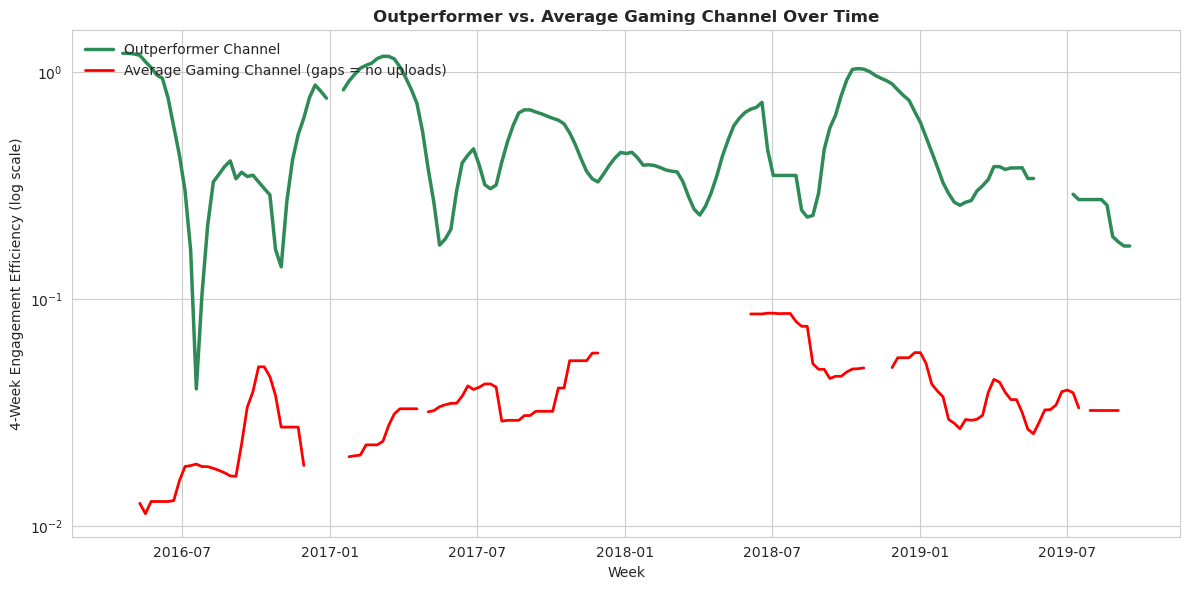

In [20]:
plot_channel_comparison(
    df=timeseries_df,
    target_channel=target_channel,
    avg_channel_id=avg_channel_id,
)

As expected, the outperformer channel achieves consistently higher engagement efficiency than the average Gaming channel throughout the observed period.
Additionally, the outperformer shows fewer and shorter inactivity gaps, indicating a more consistent upload pattern and sustained audience engagement over time.


These observations motivate our subsequent research questions. Having established that a quiet outperformer achieves consistently higher engagement efficiency and more stable activity than a comparable average Gaming channel, we next ask whether this pattern generalizes across the platform. Specifically, we investigate how quiet outperformers are distributed across content communities (RQ2), which structural or strategic choices, such as posting frequency, duration, or timing, are statistically associated with higher efficiency within each size tier and content type (RQ3), and finally, whether quiet outperformers sustain more stable growth in views and subscribers compared to similar non-outperforming channels (RQ4). Together, these questions aim to uncover the structural and behavioral factors that differentiate quiet outperformers from typical creators beyond raw engagement metrics.

# 5.Growth Analysis - Research Question 4


### Metric 1: Historical Mean Weekly Subscriber Gain

To determine if engagement efficiency translates into actual channel growth, we analyze the **Mean Weekly Subscriber Gain**.

**Methodology:**
1. **Aggregation:** We aggregate the `delta_subs` column from the `timeseries_df` by channel to compute the historical average weekly growth.
2. **Integration:** This metric is merged into the main `channel_df` (which contains the `is_outperformer` flag derived in RQ1).
3. **Filtering:** We filter the dataset to retain only the **Small-to-Mid-Sized Cohort** (subscribers < 100,000) to match the population studied in RQ1.
4. **Comparison:** We compare the growth rates of **Quiet Outperformers** vs. **Non-Outperformers**.

### Metric 1A: Unadjusted Descriptive Growth

Only considering channels with <100k subscribers!
Cohort Size (N): 94419
Outperformers (N): 2831
Non-Outperformers (N): 91588

--- Mann-Whitney U Test: mean_weekly_sub_gain ---
Hypothesis: Outperformer is greater than Non-Outperformer
Outperformer (Mean): 320.85
Non-Outperformer (Mean): 241.23
Statistic: 146077346.5, P-Value: 6.1426e-31
Result: Statistically Significant.


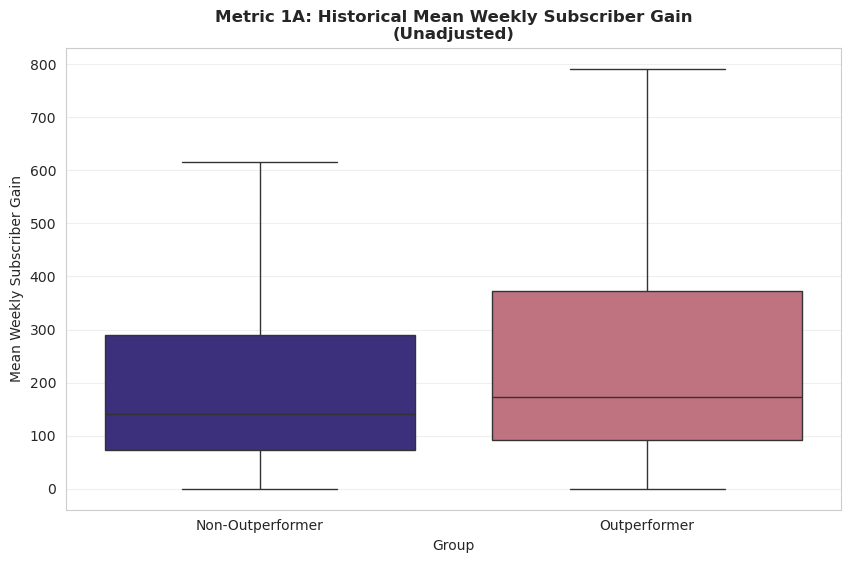

In [21]:
# Calculate Growth Metrics from Timeseries
growth_metrics = timeseries_df.groupby('channel')['delta_subs'].agg(
    mean_weekly_sub_gain='mean',
    std_weekly_sub_gain='std'
).reset_index()

# Merge & Filter Cohort
channel_df_rq4 = pd.merge(channel_df, growth_metrics, on='channel', how='left')
channel_df_rq4 = channel_df_rq4[channel_df_rq4['subscribers_cc'] < 100_000].copy()
channel_df_rq4['mean_weekly_sub_gain'] = channel_df_rq4['mean_weekly_sub_gain'].fillna(0)

# Statistics
outperformers_growth = channel_df_rq4[channel_df_rq4['is_outperformer']]
non_outperformers_growth = channel_df_rq4[~channel_df_rq4['is_outperformer']]

print("Only considering channels with <100k subscribers!")
print(f"Cohort Size (N): {len(channel_df_rq4)}")
print(f"Outperformers (N): {len(outperformers_growth)}")
print(f"Non-Outperformers (N): {len(non_outperformers_growth)}")

perform_mannwhitney_test(
    channel_df_rq4, 
    group_col='is_outperformer', 
    metric_col='mean_weekly_sub_gain', 
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Non-Outperformer'
)

# Visualization
plot_comparison_boxplot(
    data=channel_df_rq4,
    x_col='is_outperformer',
    y_col='mean_weekly_sub_gain',
    hue_col='is_outperformer',
    title='Metric 1A: Historical Mean Weekly Subscriber Gain\n(Unadjusted)',
    ylabel='Mean Weekly Subscriber Gain',
    xticklabels=['Non-Outperformer', 'Outperformer']
)

### Metric 1B: Adjusted Growth via Propensity Score Matching (PSM)

To control for confounding factors (Channel Size, Age, Video Volume, and Category), we create a balanced "Control Group" of non-outperformers that look statistically identical to our "Quiet Outperformers."

**Methodology:**
1.  **Covariates:** We match on `log(subscribers)`, `log(channel_age)`, `log(video_count)`, and enforce an **exact match** on `category`.
2.  **Propensity Score:** We estimate the probability of being an outperformer using Logistic Regression.
3.  **Matching Strategy (Optimized):**
    * **Exact Match:** We process each content category independently.
    * **Nearest Neighbor:** Within each category, we use a k-NN tree to find the single best control unit (nearest propensity score) for each treated unit.
    * **Caliper:** We enforce a strict caliper (0.01) to ensure quality matches.
    * **No Replacement:** Each control unit is used at most once.
4.  **Validation:** We check the Standardized Mean Difference (SMD) to ensure the groups are balanced ($|SMD| < 0.1$).

Original Cohort Size: 94419
Size after dropping NaNs: 94321

--- Pre-Matching Balance (SMD) ---
Target: |SMD| < 0.1
log_subs: -0.2046
log_age: -0.5140
log_videos: 0.1289

Fitting Propensity Score Model: is_outperformer ~ log_subs_std + log_age_std + log_videos_std + C(category_cc)
Starting matching (Treated=2830, Control=91491)...
Matching Complete. Matched Total: 5418
Matched Treated: 2709
Matched Control: 2709

--- Post-Matching Balance (SMD) ---
log_subs: 0.0314
log_age: -0.0058
log_videos: 0.0157

--- Mann-Whitney U Test: mean_weekly_sub_gain ---
Hypothesis: Outperformer (Matched) is greater than Control (Matched)
Outperformer (Matched) (Mean): 322.31
Control (Matched) (Mean): 265.16
Statistic: 4026845.0, P-Value: 2.6457e-10
Result: Statistically Significant.


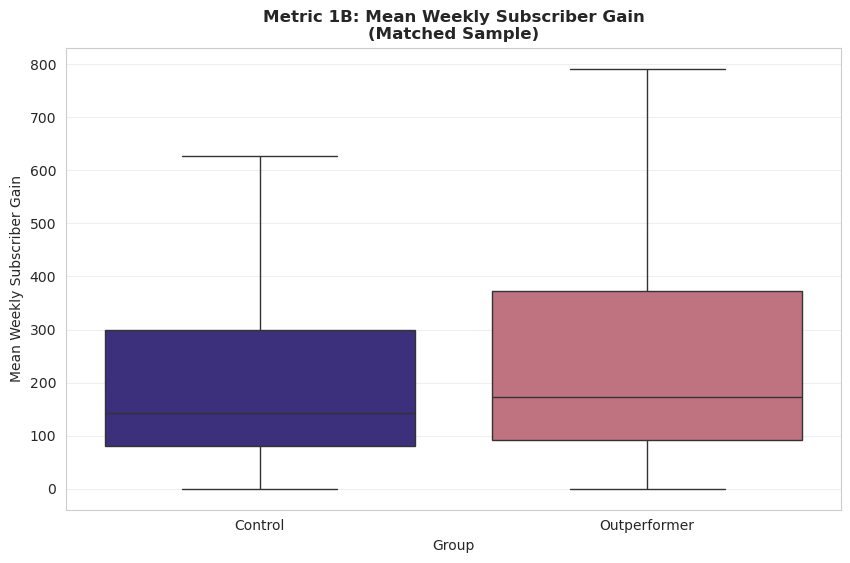

In [22]:
# Prepare Data for Propensity Score Matching
df_psm = channel_df_rq4.copy()

# Log-transform covariates
df_psm['log_subs'] = np.log10(df_psm['subscribers_cc'] + 1)
df_psm['log_age'] = np.log10(df_psm['channel_age_days'] + 1)
df_psm['log_videos'] = np.log10(df_psm['videos_cc'] + 1)

covariates = ['log_subs', 'log_age', 'log_videos']
exact_match_col = 'category_cc'

# Explicitly drop missing values before modeling
print(f"Original Cohort Size: {len(df_psm)}")
df_psm = df_psm.dropna(subset=covariates + [exact_match_col, 'is_outperformer'])
print(f"Size after dropping NaNs: {len(df_psm)}")

# Standardize Covariates
for col in covariates:
    df_psm[f'{col}_std'] = (df_psm[col] - df_psm[col].mean()) / df_psm[col].std()

# Pre-Matching Balance Check
print("\n--- Pre-Matching Balance (SMD) ---")
print("Target: |SMD| < 0.1")
for cov in covariates:
    smd = calculate_smd(df_psm, 'is_outperformer', f'{cov}_std')
    print(f"{cov}: {smd:.4f}")

# Estimate Propensity Scores and Perform Matching
# Calculate Propensity Scores
formula = f"is_outperformer ~ {' + '.join([c + '_std' for c in covariates])} + C({exact_match_col})"
df_psm['propensity_score'] = estimate_propensity_scores(df_psm, formula)

# Perform Matching
treated_df = df_psm[df_psm['is_outperformer'] == True]
control_df = df_psm[df_psm['is_outperformer'] == False]

matched_ids = match_nearest_neighbor_within_category(
    treated_df,
    control_df,
    exact_match_col='category_cc',
    caliper=0.01
)
matched_df = df_psm.loc[list(matched_ids)].copy()

print(f"Matching Complete. Matched Total: {len(matched_df)}")
print(f"Matched Treated: {matched_df['is_outperformer'].sum()}")
print(f"Matched Control: {len(matched_df) - matched_df['is_outperformer'].sum()}")

# Validate Balance (Post-Matching)
print("\n--- Post-Matching Balance (SMD) ---")
for cov in covariates:
    print(f"{cov}: {calculate_smd(matched_df, 'is_outperformer', f'{cov}_std'):.4f}")

# Statistics
perform_mannwhitney_test(
    matched_df, 
    group_col='is_outperformer', 
    metric_col='mean_weekly_sub_gain', 
    alternative='greater',
    group1_label='Outperformer (Matched)',
    group2_label='Control (Matched)'
)

# Visualization
plot_comparison_boxplot(
    data=matched_df,
    x_col='is_outperformer',
    y_col='mean_weekly_sub_gain',
    hue_col='is_outperformer',
    title='Metric 1B: Mean Weekly Subscriber Gain\n(Matched Sample)',
    ylabel='Mean Weekly Subscriber Gain',
    xticklabels=['Control', 'Outperformer']
)

### Metric 2 - Historical Mean Weekly View Gain (Matched Sample)


--- Mann-Whitney U Test: mean_weekly_view_gain ---
Hypothesis: Outperformer is less than Control
Outperformer (Mean): 35922.35
Control (Mean): 62473.29
Statistic: 2618593.0, P-Value: 9.8824e-75
Result: Statistically Significant.

Interpretation: This confirms the 'Quiet' nature of Outperformers.
Despite higher subscriber growth (Metric 1), they accumulate views significantly slower than the control group.
This suggests they prioritize efficiency and loyalty over viral reach.


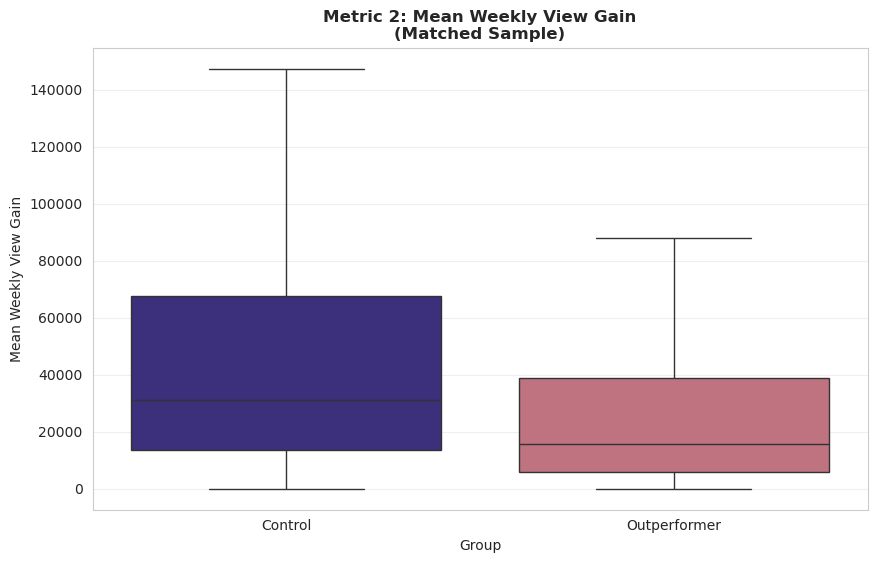

In [23]:
# Calculate View Growth Metrics from Timeseries
# We compute mean and std for views, just like we did for subscribers.
view_metrics = timeseries_df.groupby('channel')['delta_views'].agg(
    mean_weekly_view_gain='mean',
    std_weekly_view_gain='std'
).reset_index()

# Merge into the Matched DataFrame
# We use the existing matched_df to ensure we compare the exact same balanced cohort
matched_df_views = pd.merge(matched_df, view_metrics, on='channel', how='left')

# Data Cleaning
matched_df_views['mean_weekly_view_gain'] = matched_df_views['mean_weekly_view_gain'].fillna(0)

# Statistical Testing (Targeted 'Less' Hypothesis)
# We test if Outperformers have LOWER view growth than Control
stat, p_value = perform_mannwhitney_test(
    df=matched_df_views, 
    group_col='is_outperformer', 
    metric_col='mean_weekly_view_gain', 
    alternative='less',  # Testing if Outperformers < Control
    group1_label='Outperformer',
    group2_label='Control'
)

# Interpretation
if p_value < 0.05:
    print("\nInterpretation: This confirms the 'Quiet' nature of Outperformers.")
    print("Despite higher subscriber growth (Metric 1), they accumulate views significantly slower than the control group.")
    print("This suggests they prioritize efficiency and loyalty over viral reach.")

# Visualization
plot_comparison_boxplot(
    data=matched_df_views,
    x_col='is_outperformer',
    y_col='mean_weekly_view_gain',
    hue_col='is_outperformer',
    title='Metric 2: Mean Weekly View Gain\n(Matched Sample)',
    ylabel='Mean Weekly View Gain',
    xticklabels=['Control', 'Outperformer']
)

### Metric 3 - Stability & Activity Context (Metrics 3A & 3B)

**Interim Summary: The "Loyal Niche" Hypothesis**

Our analysis so far has revealed a distinct behavioral profile for Quiet Outperformers:
1.  **Metric 1 (Subscribers):** Outperformers grow their audience **significantly faster** than comparable control channels ($P_{value} \approx 0$).
2.  **Metric 2 (Views):** Surprisingly, Outperformers accumulate views **significantly slower** than control channels ($P_{value} \approx 0$).

**Interpretation:**
This divergence - High Subscriber Growth coupled with Low View Growth — suggests that Quiet Outperformers are not "Viral" channels chasing algorithmic hits (which generate massive views but fewer loyal subs). Instead, they appear to be **"Community Builders."** They attract viewers who are highly likely to convert into subscribers, even if their total view reach is smaller.

**Metric 3 Motivation:**
To validate this "Community Builder" hypothesis, we must understand their posting behavior. Do they achieve this growth through constant daily uploads, or through a more selective strategy? We introduce two new dimensions:
* **Metric 3A (Stagnation Rate):** This calculates the percentage of weeks where the channel had no subscriber growth. A high percentage suggests that growth happens in sudden spikes driven by new video uploads, rather than through a steady stream of traffic from the YouTube algorithm.
* **Metric 3B (Posting Frequency):** The average number of weekly uploads. This helps determine if stagnation is a result of audience disinterest or a lack of new content.

Calculating stagnation rates and activity metrics...
Analysis N: 5302 channels

--- Metric 3A: Stagnation Rate ---

--- Mann-Whitney U Test: stagnation_rate_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 0.17
Control (Mean): 0.10
Statistic: 4517553.0, P-Value: 8.1129e-73
Result: Statistically Significant.

--- Metric 3B: Posting Frequency ---
Median Uploads (Outperformer): 1.38
Median Uploads (Control):      0.98

--- Mann-Whitney U Test: mean_weekly_uploads ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 2.28
Control (Mean): 2.61
Statistic: 3913912.5, P-Value: 3.5284e-13
Result: Statistically Significant.


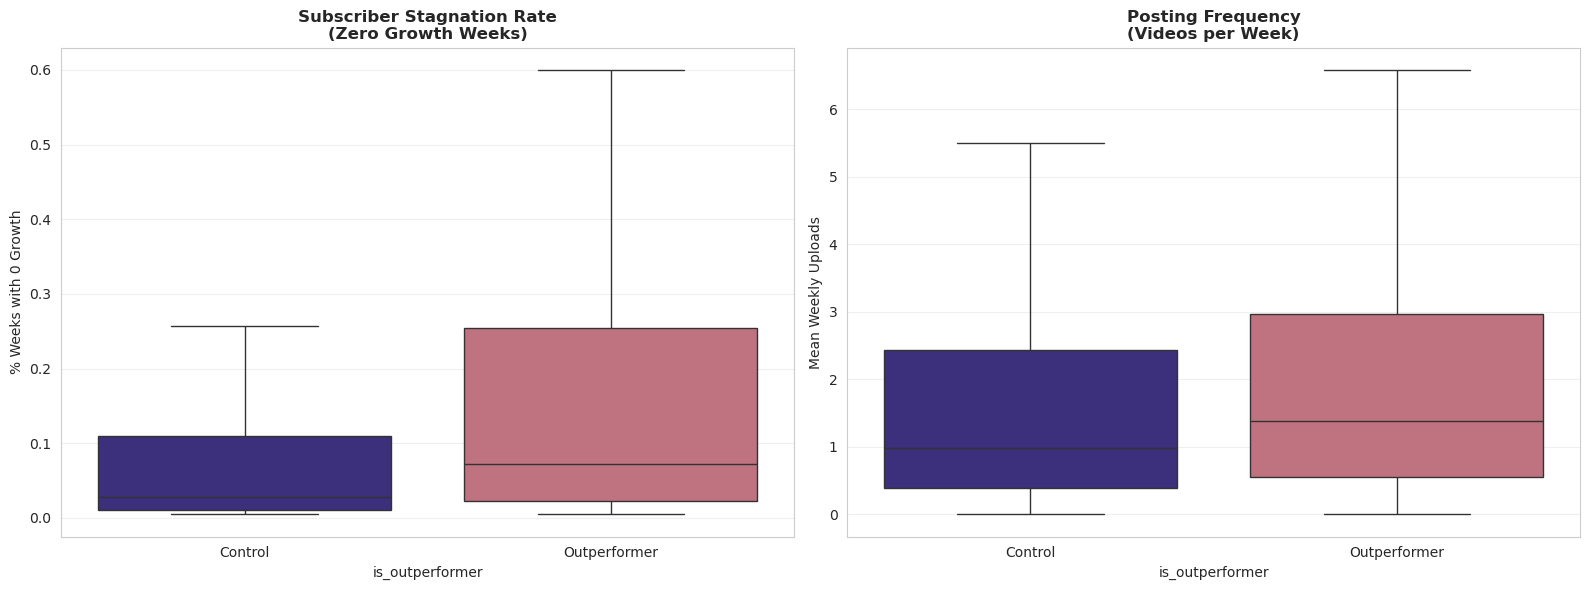

In [24]:
# Calculate Metrics from Raw Timeseries
# We must use timeseries_df because we need the weekly history, not just the average.
# First, filter timeseries to only the channels in our matched cohort.
matched_ids = matched_df['channel'].unique()
cohort_ts = timeseries_df[timeseries_df['channel'].isin(matched_ids)]

print("Calculating stagnation rates and activity metrics...")
activity_metrics = cohort_ts.groupby('channel').agg(
    stagnation_rate_subs=('delta_subs', calculate_stagnation_rate),
    mean_weekly_uploads=('delta_videos', 'mean')
).reset_index()

# Merge into Matched DataFrame
df_stability = pd.merge(matched_df, activity_metrics, on='channel', how='left')

# Data Cleaning
# Drop rows where metrics could not be computed (e.g. no history)
df_stability_clean = df_stability.dropna(subset=['stagnation_rate_subs', 'mean_weekly_uploads'])
print(f"Analysis N: {len(df_stability_clean)} channels")

# Statistical Testing

# Metric 3A: Stagnation Rate
# Hypothesis: Outperformers have MORE stagnation (bursty growth) -> 'greater'
print("\n--- Metric 3A: Stagnation Rate ---")
perform_mannwhitney_test(
    df=df_stability_clean,
    group_col='is_outperformer',
    metric_col='stagnation_rate_subs',
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Control'
)

# Metric 3B: Posting Frequency
# Hypothesis: Outperformers post MORE frequently (median) -> 'greater'
print("\n--- Metric 3B: Posting Frequency ---")
group_out = df_stability_clean[df_stability_clean['is_outperformer'] == 1]['mean_weekly_uploads']
group_ctrl = df_stability_clean[df_stability_clean['is_outperformer'] == 0]['mean_weekly_uploads']
print(f"Median Uploads (Outperformer): {group_out.median():.2f}")
print(f"Median Uploads (Control):      {group_ctrl.median():.2f}")

perform_mannwhitney_test(
    df=df_stability_clean,
    group_col='is_outperformer',
    metric_col='mean_weekly_uploads',
    alternative='greater',
    group1_label='Outperformer',
    group2_label='Control'
)

# 5. Visualization (Side-by-Side)
plot_dual_metric_boxplot(
    data=df_stability_clean,
    x_col='is_outperformer',
    metric1='stagnation_rate_subs',
    metric2='mean_weekly_uploads',
    titles=['Subscriber Stagnation Rate\n(Zero Growth Weeks)', 'Posting Frequency\n(Videos per Week)'],
    ylabels=['% Weeks with 0 Growth', 'Mean Weekly Uploads'],
    xticklabels=['Control', 'Outperformer']
)

### Metric 4: Long-Term Cumulative Growth Trajectory

To validate the hypothesis that high engagement efficiency leads to compounding growth, we analyze the **Median Cumulative Subscriber Gain** over a 3-year period.

**Methodology:**
1.  **Relative Time Alignment:** We align all channels to **Week 0** (the start of their tracking period) to compare growth *speed* rather than calendar age.
2.  **Matched Cohort:** We use the PSM-matched "twins" (identical age, size, and category at start) to ensure a fair comparison.
3.  **Metric:** We calculate the cumulative sum of subscribers gained for every week and compare the **Median** trajectory of Outperformers vs. Control.


--- Statistical Checkpoints (cum_subs) ---

Checkpoint: Week 52

--- Mann-Whitney U Test: cum_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 10283.55
Control (Mean): 8769.25
Statistic: 2495818.0, P-Value: 4.7135e-01
Result: Not Statistically Significant.

Checkpoint: Week 104

--- Mann-Whitney U Test: cum_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 17488.29
Control (Mean): 15696.61
Statistic: 1537275.0, P-Value: 1.1208e-01
Result: Not Statistically Significant.

Checkpoint: Week 160

--- Mann-Whitney U Test: cum_subs ---
Hypothesis: Outperformer is greater than Control
Outperformer (Mean): 21672.87
Control (Mean): 20194.48
Statistic: 555338.0, P-Value: 4.2650e-02
Result: Statistically Significant.


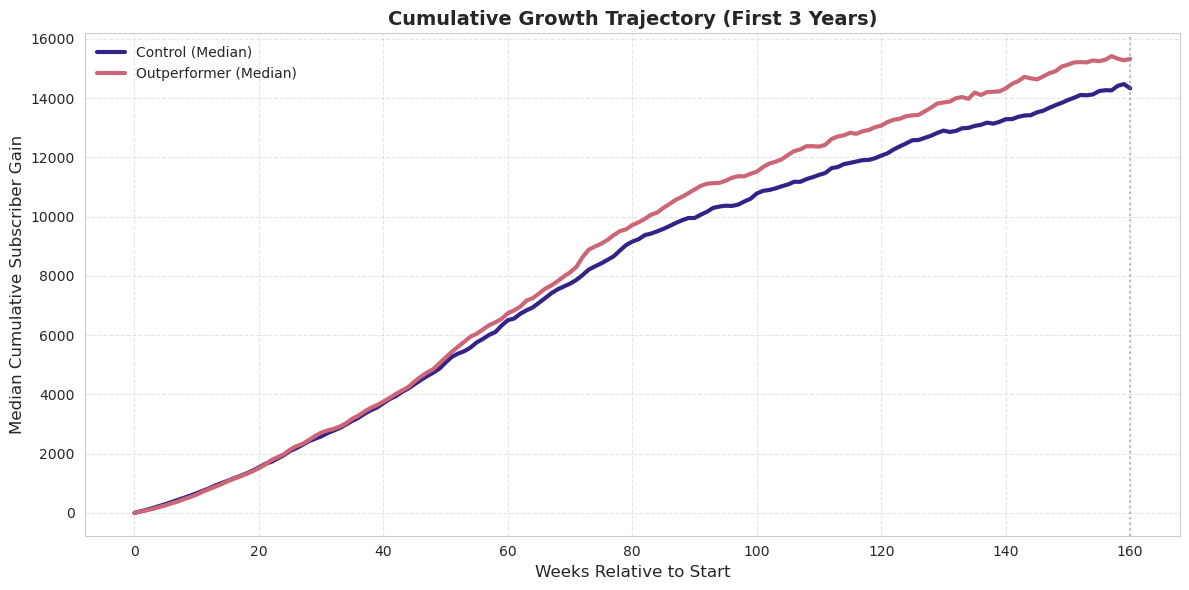

In [25]:
# Prepare Data
matched_ids = matched_df['channel'].unique()
ts_matched = timeseries_df[timeseries_df['channel'].isin(matched_ids)].copy()
channel_map = matched_df.set_index('channel')['is_outperformer'].to_dict()
ts_matched['is_outperformer'] = ts_matched['channel'].map(channel_map)

# Align Time & Calculate Cumulative Growth
ts_matched = ts_matched.sort_values(['channel', 'datetime'])
ts_matched['week_num'] = ts_matched.groupby('channel').cumcount()
ts_matched['cum_subs'] = ts_matched.groupby('channel')['delta_subs'].cumsum()

# Statistical Checkpoints
check_growth_milestones(
    df=ts_matched, 
    milestones=[52, 104, 160], # Year 1, Year 2, Year 3
    metric_col='cum_subs'
)

# Aggregate Trajectories (Median)
trajectory_df = ts_matched.groupby(['is_outperformer', 'week_num'])['cum_subs'].median().reset_index()

# Truncate: Cut off at Week 160 (approx 3 years)
trajectory_df = trajectory_df[trajectory_df['week_num'] <= 160]

# Visualization
plot_growth_trajectory(
    trajectory_df=trajectory_df,
    x_col='week_num',
    y_col='cum_subs',
    hue_col='is_outperformer',
    title="Cumulative Growth Trajectory (First 3 Years)",
    xlabel="Weeks Relative to Start",
    ylabel="Median Cumulative Subscriber Gain"
)

### **Final Conclusion: The Anatomy of a "Quiet Outperformer"**

**Synthesis of Findings:**

* **The "Quiet" Nature (Metrics 2 & 3A):**
    * **Lower Viral Reach:** Unlike typical successful channels that chase massive view counts, Quiet Outperformers actually gain **significantly fewer views** per week (Metric 2). They do not rely on "viral hits" or algorithmic jackpots.
    * **Bursty Growth:** They experience more "quiet" weeks (Metric 3A: Higher Stagnation Rate) where they see zero growth. This implies they are not riding a constant wave of algorithmic recommendations (which would provide a steady trickle of views and subscribers). Instead, their growth is likely tied directly to their specific content releases.

* **The "Outperformance" (Metric 1):**
    * **High Conversion:** Despite getting fewer views, they achieve **significantly higher subscriber growth** (Metric 1). This is the "Outperformer" magic: their **Engagement Efficiency** (likes/comments per view) is so high that a single view is far more likely to convert into a subscriber than it is for a control channel. They build **Loyalty**, not just Reach.

* **The Strategy: "Consistent Quality" (Metric 3B):**
    * **Active, Not Spammy:** The Control group is distorted by "spammers" - channels that upload dozens of videos a week to fish for views (high mean uploads, low median).
    * **Reliable Creators:** By contrast, the **typical (median) Outperformer** posts *more frequently* (1.38 videos/week) than the typical Control channel (0.98 videos/week). They are disciplined creators who stick to a schedule, avoiding both "spam" and "abandonment."

* **Long-Term Growth (Metric 4):**

    * **No Head Start**: Statistical tests confirm no significant difference in growth for the first two years (Weeks 52 & 104), proving that Outperformers do not possess an inherent advantage.
    * **Compounding Payoff**: The strategy is a long-term investment. A statistically significant lead ($p < 0.05$) only emerges by Week 160 (Year 3), confirming that the compounding value of a loyal community takes time to break away from the volatility of viral chasing.

**Summary Statement:**
> *"Quiet Outperformers are **Community Builders**. They reject the 'viral lottery' strategy of chasing massive view counts. Instead, they maintain a disciplined, higher-than-average posting schedule of high-efficiency content. While this approach leads to more periods of 'stagnation' (fewer passive/algorithmic views), it generates significantly higher long-term subscriber growth by converting viewers into loyal fans at an exceptional rate."*

# Plots Data Story

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import os
import pandas as pd
import numpy as np

# Create directory
output_dir = "website/assets/plots"
os.makedirs(output_dir, exist_ok=True)

# --- Configuration ---
COLOR_CONTROL = "#332288"       
COLOR_OUTPERFORMER = "#CC6677"   
COLORS = [COLOR_CONTROL, COLOR_OUTPERFORMER]

# Standard Layout
common_layout = dict(
    font=dict(family="Arial, sans-serif", size=14, color="#2c3e50"),
    plot_bgcolor="white",
    paper_bgcolor="white",
    autosize=True,
    margin=dict(l=30, r=30, t=80, b=50), 
    showlegend=False,
    modebar=dict(orientation='v', bgcolor='rgba(0,0,0,0)'),
)

def lock_axes(fig):
    fig.update_xaxes(fixedrange=True)
    fig.update_yaxes(fixedrange=True, showgrid=True, gridcolor="#ecf0f1")

# ==============================================================================
# 🔹 HELPER FUNCTION: Dynamic Zoom Limit
# ==============================================================================
def get_y_ceiling(df, col_name, zoom=True, multiplier=1.0):
    if not zoom:
        return None
    subset = df[col_name].dropna()
    if subset.empty: return None
    Q1 = subset.quantile(0.25)
    Q3 = subset.quantile(0.75)
    IQR = Q3 - Q1
    upper_fence = Q3 + (multiplier * IQR)
    return upper_fence * 1.1

# ==============================================================================
# Plot 1: Unadjusted Growth (Metric 1A) - Kept separate as requested
# ==============================================================================
fig1 = go.Figure()
fig1.add_trace(go.Box(
    y=channel_df_rq4[channel_df_rq4['is_outperformer'] == 0]['mean_weekly_sub_gain'],
    name="Control", marker_color=COLOR_CONTROL, boxpoints=False, showlegend=False
))
fig1.add_trace(go.Box(
    y=channel_df_rq4[channel_df_rq4['is_outperformer'] == 1]['mean_weekly_sub_gain'],
    name="Outperformer", marker_color=COLOR_OUTPERFORMER, boxpoints=False, showlegend=False
))


fig1.update_layout(**common_layout)
fig1.update_layout(title="<b>Raw Subscriber Growth</b><br><span style='font-size:12px;color:gray'>Unadjusted comparison (Zoomed to distribution)</span>")
fig1.update_yaxes(title_text="Mean Weekly Subscriber Gain")
y_limit = get_y_ceiling(channel_df_rq4, 'mean_weekly_sub_gain', zoom=True)
if y_limit: fig1.update_yaxes(range=[0, y_limit])
lock_axes(fig1)

config = {'displayModeBar': False, 'responsive': True}
fig1.write_html(f"{output_dir}/metric1a_unadjusted_growth.html", config=config)
print("Saved Plot 1")


# ==============================================================================
# COMBINED PLOT: Matched Comparison & Stability (1 Row, 4 Columns)
# ==============================================================================
fig_combined = make_subplots(
    rows=1, cols=4,
    subplot_titles=(
        "<b>Subscriber Gain</b><br>(Growth)",
        "<b>View Gain</b><br>(Reach)", 
        "<b>Stagnation Rate</b><br>(Stability)", 
        "<b>Posting Frequency</b><br>(Activity)"
    ),
    horizontal_spacing=0.08 
)

# --- COL 1: Subscriber Gain (Matched) ---
fig_combined.add_trace(go.Box(y=matched_df[matched_df['is_outperformer']==0]['mean_weekly_sub_gain'], name='Control', marker_color=COLOR_CONTROL, showlegend=False, boxpoints=False), row=1, col=1)
fig_combined.add_trace(go.Box(y=matched_df[matched_df['is_outperformer']==1]['mean_weekly_sub_gain'], name='Outperformer', marker_color=COLOR_OUTPERFORMER, showlegend=False, boxpoints=False), row=1, col=1)

# --- COL 2: View Gain (Matched) ---
# Enable legend here to show it once
fig_combined.add_trace(go.Box(y=matched_df_views[matched_df_views['is_outperformer']==0]['mean_weekly_view_gain'], name='Control', marker_color=COLOR_CONTROL, showlegend=True, boxpoints=False), row=1, col=2)
fig_combined.add_trace(go.Box(y=matched_df_views[matched_df_views['is_outperformer']==1]['mean_weekly_view_gain'], name='Outperformer', marker_color=COLOR_OUTPERFORMER, showlegend=True, boxpoints=False), row=1, col=2)

# --- COL 3: Stagnation Rate ---
fig_combined.add_trace(go.Box(y=df_stability_clean[df_stability_clean['is_outperformer']==0]['stagnation_rate_subs'], name='Control', marker_color=COLOR_CONTROL, showlegend=False, boxpoints=False), row=1, col=3)
fig_combined.add_trace(go.Box(y=df_stability_clean[df_stability_clean['is_outperformer']==1]['stagnation_rate_subs'], name='Outperformer', marker_color=COLOR_OUTPERFORMER, showlegend=False, boxpoints=False), row=1, col=3)

# --- COL 4: Posting Frequency ---
fig_combined.add_trace(go.Box(y=df_stability_clean[df_stability_clean['is_outperformer']==0]['mean_weekly_uploads'], name='Control', marker_color=COLOR_CONTROL, showlegend=False, boxpoints=False), row=1, col=4)
fig_combined.add_trace(go.Box(y=df_stability_clean[df_stability_clean['is_outperformer']==1]['mean_weekly_uploads'], name='Outperformer', marker_color=COLOR_OUTPERFORMER, showlegend=False, boxpoints=False), row=1, col=4)

# --- LAYOUT & STYLING ---
fig_combined.update_layout(
    font=dict(family="Arial, sans-serif", size=14, color="#2c3e50"),
    plot_bgcolor="white", paper_bgcolor="white", autosize=True,
    modebar=dict(orientation='v', bgcolor='rgba(0,0,0,0)'),
    margin=dict(l=50, r=50, t=100, b=80),
    title=dict(text="<b>Matched Performance & Stability Metrics</b>", y=0.98, x=0.5, xanchor='center', yanchor='top'),
    legend=dict(
        orientation="h", 
        yanchor="bottom", 
        y=-0.3, 
        xanchor="center", 
        x=0.5,
        itemclick=False,     
        itemdoubleclick=False 
    )
)

# --- AXIS CONFIGURATION (Apply Zooms) ---

# Col 1: Subs
y_lim1 = get_y_ceiling(matched_df, 'mean_weekly_sub_gain', zoom=True)
fig_combined.update_yaxes(title_text="Mean Weekly Subs", row=1, col=1, fixedrange=True, showgrid=True, gridcolor="#ecf0f1")
if y_lim1: fig_combined.update_yaxes(range=[0, y_lim1], row=1, col=1)

# Col 2: Views
y_lim2 = get_y_ceiling(matched_df_views, 'mean_weekly_view_gain', zoom=True)
fig_combined.update_yaxes(title_text="Mean Weekly Views", row=1, col=2, fixedrange=True, showgrid=True, gridcolor="#ecf0f1")
if y_lim2: fig_combined.update_yaxes(range=[0, y_lim2], row=1, col=2)

# Col 3: Stagnation
y_lim3 = get_y_ceiling(df_stability_clean, 'stagnation_rate_subs', zoom=True)
fig_combined.update_yaxes(title_text="% Weeks 0 Growth", row=1, col=3, fixedrange=True, showgrid=True, gridcolor="#ecf0f1")
if y_lim3: fig_combined.update_yaxes(range=[0, y_lim3], row=1, col=3)

# Col 4: Frequency
y_lim4 = get_y_ceiling(df_stability_clean, 'mean_weekly_uploads', zoom=True)
fig_combined.update_yaxes(title_text="Uploads / Week", row=1, col=4, fixedrange=True, showgrid=True, gridcolor="#ecf0f1")
if y_lim4: fig_combined.update_yaxes(range=[0, y_lim4], row=1, col=4)

# Apply common X-axis labels
fig_combined.update_xaxes(title_text="", ticktext=["Control", "Outperformer"], tickvals=[0, 1], fixedrange=True)

# Save
fig_combined.write_html(f"{output_dir}/rq4_combined_metrics.html", config=config)
print("Saved Combined Plot: rq4_combined_metrics.html")

Saved Plot 1
Saved Combined Plot: rq4_combined_metrics.html


# Median Cumulative Growth Trajectory

In [ ]:
import plotly.graph_objects as go
import pandas as pd
from scipy.stats import mannwhitneyu

# --- Configuration ---
COLOR_CONTROL = "#332288"      
COLOR_OUTPERFORMER = "#CC6677" 

# 1. Prepare Data
matched_ids = matched_df['channel'].unique()
ts_matched = timeseries_df[timeseries_df['channel'].isin(matched_ids)].copy()
channel_map = matched_df.set_index('channel')['is_outperformer'].to_dict()
ts_matched['is_outperformer'] = ts_matched['channel'].map(channel_map)

# 2. Align Time & Calculate Cumulative Growth
ts_matched = ts_matched.sort_values(['channel', 'datetime'])
ts_matched['week_num'] = ts_matched.groupby('channel').cumcount()
ts_matched['cum_subs'] = ts_matched.groupby('channel')['delta_subs'].cumsum()

# --- DEBUGGING: Statistical Significance Check ---
print("\n--- Statistical Checkpoints (Cumulative Growth) ---")
for week in [52, 104, 160]: # Year 1, Year 2, Year 3
    data_at_week = ts_matched[ts_matched['week_num'] == week]
    g_out = data_at_week[data_at_week['is_outperformer'] == True]['cum_subs']
    g_ctrl = data_at_week[data_at_week['is_outperformer'] == False]['cum_subs']
    
    n_out = len(g_out)
    n_ctrl = len(g_ctrl)
    
    if n_out > 0 and n_ctrl > 0:
        stat, p = mannwhitneyu(g_out, g_ctrl, alternative='greater')
        sig_label = "SIGNIFICANT" if p < 0.05 else "Not Significant"
        print(f"Week {week}: N_out={n_out}, N_ctrl={n_ctrl} | P-Value={p:.4f} -> {sig_label}")
    else:
        print(f"Week {week}: Not enough data")

# 3. Aggregate Trajectories (Median Only)
trajectory_df = ts_matched.groupby(['is_outperformer', 'week_num'])['cum_subs'].median().reset_index()

# --- TRUNCATE: Cut off at Week 160 (approx 3 years) ---
trajectory_df = trajectory_df[trajectory_df['week_num'] <= 160] 

# Separate groups
traj_out = trajectory_df[trajectory_df['is_outperformer'] == True]
traj_ctrl = trajectory_df[trajectory_df['is_outperformer'] == False]

# 4. Create Plot
fig_traj = go.Figure()

# Outperformer Line
fig_traj.add_trace(go.Scatter(
    x=traj_out['week_num'], 
    y=traj_out['cum_subs'],
    mode='lines',
    name='Outperformer (Median)',
    line=dict(color=COLOR_OUTPERFORMER, width=4)
))

# Control Line
fig_traj.add_trace(go.Scatter(
    x=traj_ctrl['week_num'], 
    y=traj_ctrl['cum_subs'],
    mode='lines',
    name='Control (Median)',
    line=dict(color=COLOR_CONTROL, width=4)
))

# 5. Styling
fig_traj.update_layout(
    font=dict(family="Arial, sans-serif", size=14, color="#2c3e50"),
    plot_bgcolor="white",
    paper_bgcolor="white",
    autosize=True,
    margin=dict(l=50, r=50, t=80, b=50),
    title=dict(
        # Updated Title
        text="<b>Cumulative Growth Trajectory</b><br><span style='font-size:12px;color:gray'>Median cumulative subscribers (First 3 Years)</span>",
        x=0.5, y=0.95
    ),
    xaxis=dict(title="Weeks Relative to Start", showgrid=False, linecolor='black'),
    yaxis=dict(title="Cumulative Subscriber Gain", showgrid=True, gridcolor="#ecf0f1"),
    legend=dict(x=0.05, y=0.95),
    modebar=dict(orientation='v', bgcolor='rgba(0,0,0,0)'),
)

fig_traj.update_xaxes(fixedrange=True)
fig_traj.update_yaxes(fixedrange=True)

output_dir = "website/assets/plots"
fig_traj.write_html(f"{output_dir}/rq4_growth_trajectory.html", config={'displayModeBar': False})
print("Saved Plot: rq4_growth_trajectory.html")


--- Statistical Checkpoints (Cumulative Growth) ---
Week 52: N_out=2178, N_ctrl=2289 | P-Value=0.4714 -> Not Significant
Week 104: N_out=1632, N_ctrl=1840 | P-Value=0.1121 -> Not Significant
Week 160: N_out=918, N_ctrl=1159 | P-Value=0.0426 -> SIGNIFICANT
Saved Plot: rq4_growth_trajectory.html
